## Data Preparation and Preprocessing

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from modeling import config
from modeling.models import fit_all
from modeling import evaluation as ev
from modeling.derive import to_inflation, to_purchasing_power, derive_all

PROC = ROOT / 'datasets' / 'processed'
OUT  = ROOT / 'datasets' / 'outputs'

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.float_format', '{:.3f}'.format)

print('Project root:', ROOT)
print('Target series:', config.TARGET_AREA, '-', config.TARGET_ITEM)
print('Data period:', config.DATA_START.date(), 'to', config.DATA_END.date())
print('Eligible models:', config.PROPOSAL_MODELS)
# print('Extra (reported only):', config.EXTRA_MODELS)

Project root: d:\JUDY\BSIT 4YR\ELEC4\elec4_etr_modif\PresyoPH-main
Target series: PHILIPPINES - 0 - ALL ITEMS
Data period: 2018-01-01 to 2026-08-01
Eligible models: ['ARIMA', 'Linear Regression', 'Moving Average']


In [3]:
cpi_raw    = pd.read_csv(PROC / 'cpi_clean.csv',    parse_dates=['date'])
inf_raw    = pd.read_csv(PROC / 'inflation_clean.csv', parse_dates=['date'])
pp_raw     = pd.read_csv(PROC / 'purchasing_power_clean.csv', parse_dates=['date'])
fies_raw   = pd.read_csv(PROC / 'fies_clean.csv')

inventory = pd.DataFrame([
    {'dataset': 'CPI',                      'rows': len(cpi_raw),    'areas': cpi_raw['area'].nunique(), 'categories': cpi_raw['category'].nunique(), 'months': cpi_raw['date'].nunique(), 'missing': int(cpi_raw['value'].isna().sum()), 'duplicates': int(cpi_raw.duplicated(subset=['date','area','category']).sum())},
    {'dataset': 'Inflation',                'rows': len(inf_raw),    'areas': inf_raw['area'].nunique(), 'categories': inf_raw['category'].nunique(), 'months': inf_raw['date'].nunique(), 'missing': int(inf_raw['value'].isna().sum()), 'duplicates': int(inf_raw.duplicated(subset=['date','area','category']).sum())},
    {'dataset': 'Purchasing power',         'rows': len(pp_raw),     'areas': pp_raw['area'].nunique(),  'categories': np.nan,                'months': pp_raw['date'].nunique(), 'missing': int(pp_raw['value'].isna().sum()), 'duplicates': int(pp_raw.duplicated(subset=['date','area']).sum())},
    {'dataset': 'FIES 2023',                'rows': len(fies_raw),   'areas': fies_raw['area'].nunique(), 'categories': np.nan,             'months': np.nan,                'missing': int(fies_raw.isna().sum().sum()), 'duplicates': int(fies_raw.duplicated(subset=['year','area','income_group','indicator']).sum())},
])
inventory

,dataset,rows,areas,categories,months,missing,duplicates
0,CPI,174720,120,14.000,104.000,0,0
1,Inflation,154560,120,14.000,92.000,0,0
2,Purchasing power,12480,120,NaN,104.000,0,0
3,FIES 2023,4554,138,NaN,NaN,0,0


In [4]:
print('CPI date range:', cpi_raw['date'].min().date(), 'to', cpi_raw['date'].max().date())
print('Inflation date range:', inf_raw['date'].min().date(), 'to', inf_raw['date'].max().date())
print('Purchasing power date range:', pp_raw['date'].min().date(), 'to', pp_raw['date'].max().date())
print('FIES year:', sorted(fies_raw['year'].unique()))
print()
print('CPI preview:')
print(cpi_raw.head(6).to_string(index=False))

CPI date range: 2018-01-01 to 2026-08-01
Inflation date range: 2019-01-01 to 2026-08-01
Purchasing power date range: 2018-01-01 to 2026-08-01
FIES year: [np.int64(2023)]

CPI preview:
      date     area                                                                category   value  base_year
2018-01-01 ....Abra                                                           0 - ALL ITEMS  98.200       2018
2018-01-01 ....Abra                                   01 - FOOD AND NON-ALCOHOLIC BEVERAGES  95.600       2018
2018-01-01 ....Abra                                    02 - ALCOHOLIC BEVERAGES AND TOBACCO  92.400       2018
2018-01-01 ....Abra                                              03 - CLOTHING AND FOOTWEAR  98.700       2018
2018-01-01 ....Abra                  04 - HOUSING, WATER, ELECTRICITY, GAS, AND OTHER FUELS 104.800       2018
2018-01-01 ....Abra 05 - FURNISHINGS, HOUSEHOLD EQUIPMENT AND ROUTINE HOUSEHOLD MAINTENANCE  99.400       2018


In [5]:
# National all-items CPI series used for modeling
cpi = (
    cpi_raw.assign(area=cpi_raw['area'].str.lstrip('.').str.strip())
      .query("area == 'PHILIPPINES' and category == '0 - ALL ITEMS'")
      .set_index('date')['value']
      .sort_index()
      .asfreq('MS')
)
cpi.name = 'cpi'
print('National all-items CPI observations:', len(cpi))
print('Period:', cpi.index.min().date(), 'to', cpi.index.max().date())
print('Missing:', int(cpi.isna().sum()))
display(cpi.describe().to_frame().T)

National all-items CPI observations: 104
Period: 2018-01-01 to 2026-08-01
Missing: 0


,count,mean,std,min,25%,50%,75%,max
cpi,104.000,115.091,11.532,97.200,103.875,113.650,125.775,136.500


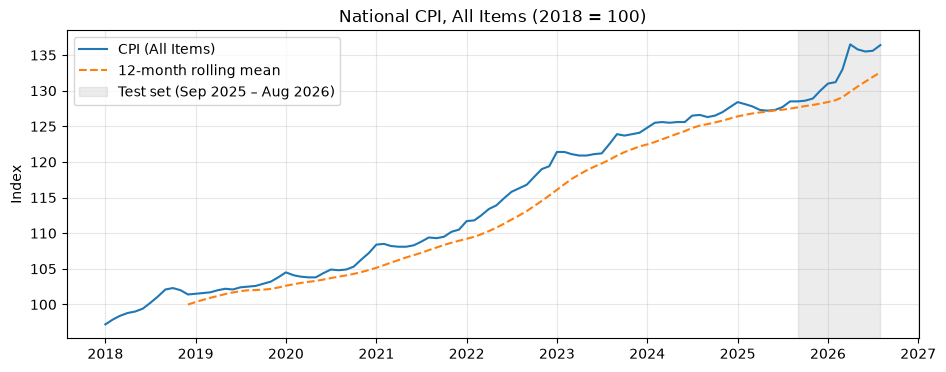

,first,last,mean,change within year (%)
date,,,,
2018,97.200,101.400,99.983,4.321
2019,101.500,103.800,102.375,2.266
2020,104.500,107.200,104.825,2.584
2021,108.400,110.500,108.942,1.937
2022,111.700,119.400,115.283,6.893
2023,121.400,124.100,122.175,2.224
2024,124.800,127.700,126.100,2.324
2025,128.400,130.000,128.192,1.246
2026,131.000,136.400,134.375,4.122


In [6]:
fig, ax = plt.subplots()
ax.plot(cpi, label='CPI (All Items)')
ax.plot(cpi.rolling(12).mean(), label='12-month rolling mean', linestyle='--')
ax.axvspan(config.TEST_START, config.TEST_END, color='grey', alpha=0.15,
           label='Test set (Sep 2025 – Aug 2026)')
ax.set_title('National CPI, All Items (2018 = 100)')
ax.set_ylabel('Index')
ax.legend()
plt.show()

yearly = cpi.groupby(cpi.index.year).agg(['first', 'last', 'mean'])
yearly['change within year (%)'] = (yearly['last'] / yearly['first'] - 1) * 100
display(yearly)

In [8]:
quality = pd.DataFrame([
    {'check': 'Missing values (CPI)',            'result': int(cpi_raw['value'].isna().sum()),                      'status': 'PASS' if cpi_raw['value'].isna().sum() == 0 else 'FAIL'},
    {'check': 'Missing values (Inflation)',      'result': int(inf_raw['value'].isna().sum()),                     'status': 'PASS' if inf_raw['value'].isna().sum() == 0 else 'FAIL'},
    {'check': 'Missing values (Purchasing power)','result': int(pp_raw['value'].isna().sum()),                    'status': 'PASS' if pp_raw['value'].isna().sum() == 0 else 'FAIL'},
    {'check': 'Missing values (FIES)',           'result': int(fies_raw.isna().sum().sum()),                       'status': 'PASS' if fies_raw.isna().sum().sum() == 0 else 'FAIL'},
    {'check': 'Duplicate observations (CPI)',    'result': int(cpi_raw.duplicated(subset=['date','area','category']).sum()), 'status': 'PASS' if cpi_raw.duplicated(subset=['date','area','category']).sum() == 0 else 'FAIL'},
    {'check': 'Duplicate observations (FIES)',   'result': int(fies_raw.duplicated(subset=['year','area','income_group','indicator']).sum()), 'status': 'PASS' if fies_raw.duplicated(subset=['year','area','income_group','indicator']).sum() == 0 else 'FAIL'},
    {'check': 'CPI months per area/category',    'result': int(cpi_raw.groupby(['area','category'])['date'].nunique().min()), 'status': 'PASS'},
    {'check': 'CPI expected vs actual rows',     'result': f"{len(cpi_raw)} vs {cpi_raw['area'].nunique()*cpi_raw['category'].nunique()*cpi_raw['date'].nunique()}", 'status': 'PASS' if len(cpi_raw) == cpi_raw['area'].nunique()*cpi_raw['category'].nunique()*cpi_raw['date'].nunique() else 'FAIL'},
])
display(quality.to_string(index=False))

'                            check           result status\n             Missing values (CPI)                0   PASS\n       Missing values (Inflation)                0   PASS\nMissing values (Purchasing power)                0   PASS\n            Missing values (FIES)                0   PASS\n     Duplicate observations (CPI)                0   PASS\n    Duplicate observations (FIES)                0   PASS\n     CPI months per area/category              104   PASS\n      CPI expected vs actual rows 174720 vs 174720   PASS'

## Algorithm Implementation, Model Development, and Experimentation

Train: Jan 2018 – Aug 2025  (92 months)
Test:  Sep 2025  – Aug 2026  (12 months)
Split: 88.5% / 11.5%


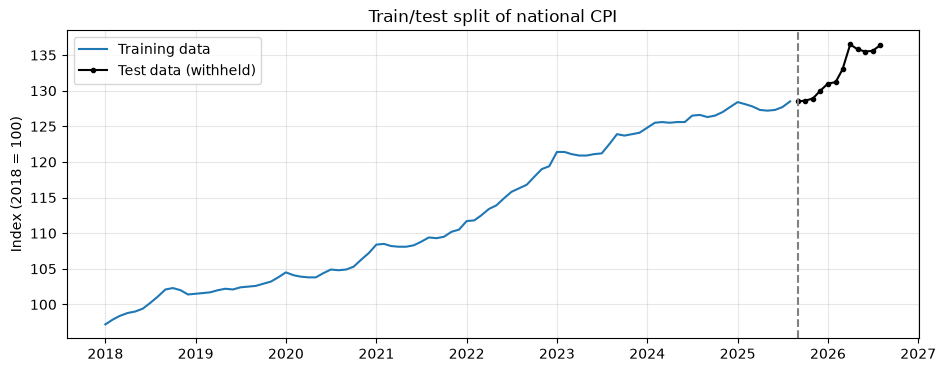

In [9]:
train = cpi[: config.TRAIN_END]
test  = cpi[config.TEST_START : config.TEST_END]

print(f'Train: {train.index[0]:%b %Y} – {train.index[-1]:%b %Y}  ({len(train)} months)')
print(f'Test:  {test.index[0]:%b %Y}  – {test.index[-1]:%b %Y}  ({len(test)} months)')
print(f'Split: {len(train)/len(cpi):.1%} / {len(test)/len(cpi):.1%}')

fig, ax = plt.subplots()
ax.plot(train, label='Training data')
ax.plot(test, color='black', marker='o', markersize=3, label='Test data (withheld)')
ax.axvline(config.TEST_START, color='grey', linestyle='--')
ax.set_title('Train/test split of national CPI')
ax.set_ylabel('Index (2018 = 100)')
ax.legend()
plt.show()

In [10]:
results = fit_all(train, horizon=config.HORIZON)
params = {name: r.params for name, r in results.items()}
display(pd.DataFrame(params).T)

,order,seasonal_order,aic,drift_per_month,intercept,slope_per_month,r_squared,k,level
ARIMA,"(1, 1, 0)","(0, 0, 0, 0)",116.714,0.349,NaN,NaN,NaN,NaN,NaN
Linear Regression,NaN,NaN,NaN,NaN,95.367,0.375,0.968,NaN,NaN
Moving Average,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000,127.833


In [11]:
arima = results['ARIMA']
cand = arima.candidates.copy()
cand['order'] = cand['order'].astype(str)
cand['seasonal_order'] = cand['seasonal_order'].astype(str)
display(cand[['order','seasonal_order','aic','n_params','converged','selected']].sort_values('aic').reset_index(drop=True))
print('\nChosen ARIMA order:', arima.params['order'], '| seasonal:', arima.params['seasonal_order'],
      '| drift/month:', round(arima.params['drift_per_month'], 4))

,order,seasonal_order,aic,n_params,converged,selected
0,"(0, 1, 1)","(1, 0, 0, 12)",115.677,4,True,False
1,"(1, 1, 0)","(0, 0, 0, 0)",116.714,3,True,True
2,"(1, 1, 0)","(1, 0, 0, 12)",116.719,4,True,False
3,"(0, 1, 1)","(0, 0, 0, 0)",116.774,3,True,False
4,"(1, 1, 1)","(1, 0, 0, 12)",117.665,5,True,False
5,"(0, 1, 2)","(1, 0, 0, 12)",117.675,5,True,False
6,"(2, 1, 0)","(1, 0, 0, 12)",117.727,5,True,False
7,"(2, 1, 2)","(0, 0, 0, 0)",117.775,6,True,False
8,"(2, 1, 0)","(0, 0, 0, 0)",118.194,4,True,False
9,"(1, 1, 1)","(0, 0, 0, 0)",118.339,4,True,False



Chosen ARIMA order: (1, 1, 0) | seasonal: (0, 0, 0, 0) | drift/month: 0.3487


CPI = 95.367 + 0.3751 × t   (R² = 0.968)
Durbin–Watson statistic: 0.068 (near 2 = independent residuals)


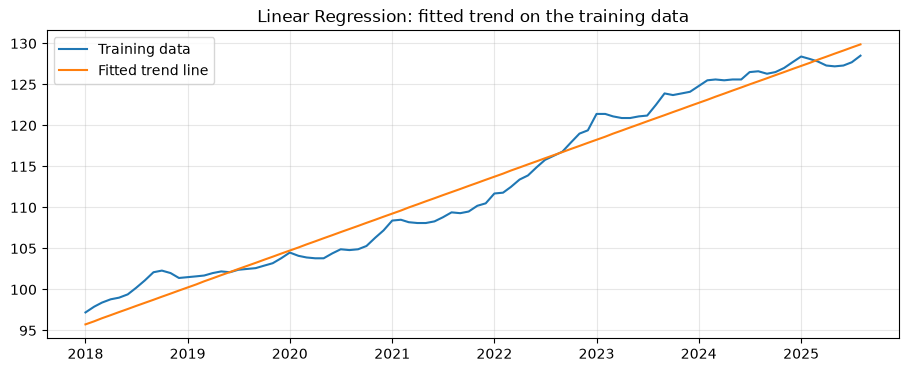

In [12]:
from statsmodels.stats.stattools import durbin_watson

lr = results['Linear Regression']
print(f"CPI = {lr.params['intercept']:.3f} + {lr.params['slope_per_month']:.4f} × t   (R² = {lr.params['r_squared']:.3f})")
print(f"Durbin\u2013Watson statistic: {durbin_watson(lr.fitted.resid):.3f} (near 2 = independent residuals)")

t = np.arange(1, len(train) + 1)
fig, ax = plt.subplots()
ax.plot(train, label='Training data')
ax.plot(train.index, lr.fitted.fittedvalues, color='tab:orange', label='Fitted trend line')
ax.set_title('Linear Regression: fitted trend on the training data')
ax.legend()
plt.show()

In [13]:
ma = results['Moving Average']
print(f"Chosen window: k = {ma.params['k']}  →  forecast level {ma.params['level']:.2f}")
display(ma.candidates)

Chosen window: k = 3  →  forecast level 127.83


,k,validation_rmse
0,3,1.413
1,6,1.715
2,12,2.464


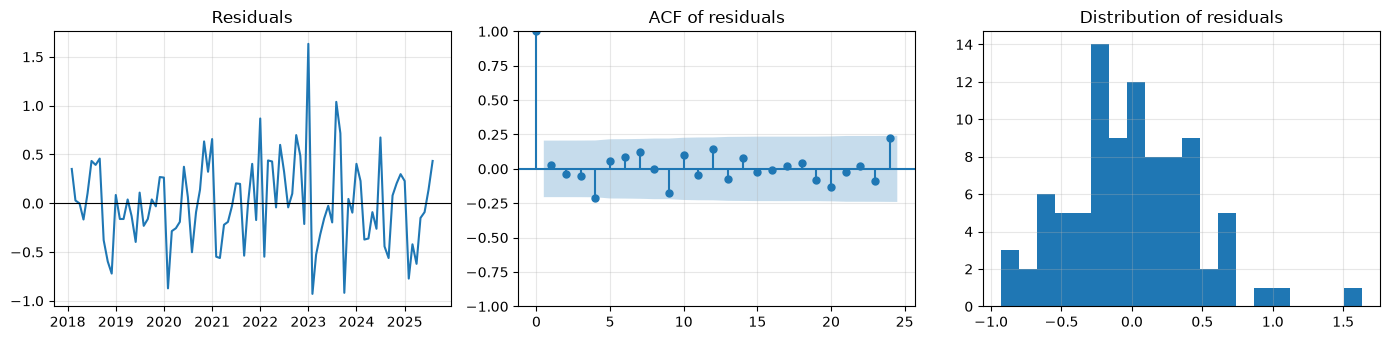

    lb_stat  lb_pvalue
6     5.874      0.437
12   14.135      0.292
24   25.801      0.363


In [14]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

resid = arima.fitted.resid.iloc[1:]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(resid); axes[0].axhline(0, color='black', linewidth=0.8); axes[0].set_title('Residuals')
plot_acf(resid, lags=24, ax=axes[1], title='ACF of residuals')
axes[2].hist(resid, bins=20); axes[2].set_title('Distribution of residuals')
fig.tight_layout()
plt.show()

print(acorr_ljungbox(resid, lags=[6, 12, 24], return_df=True))

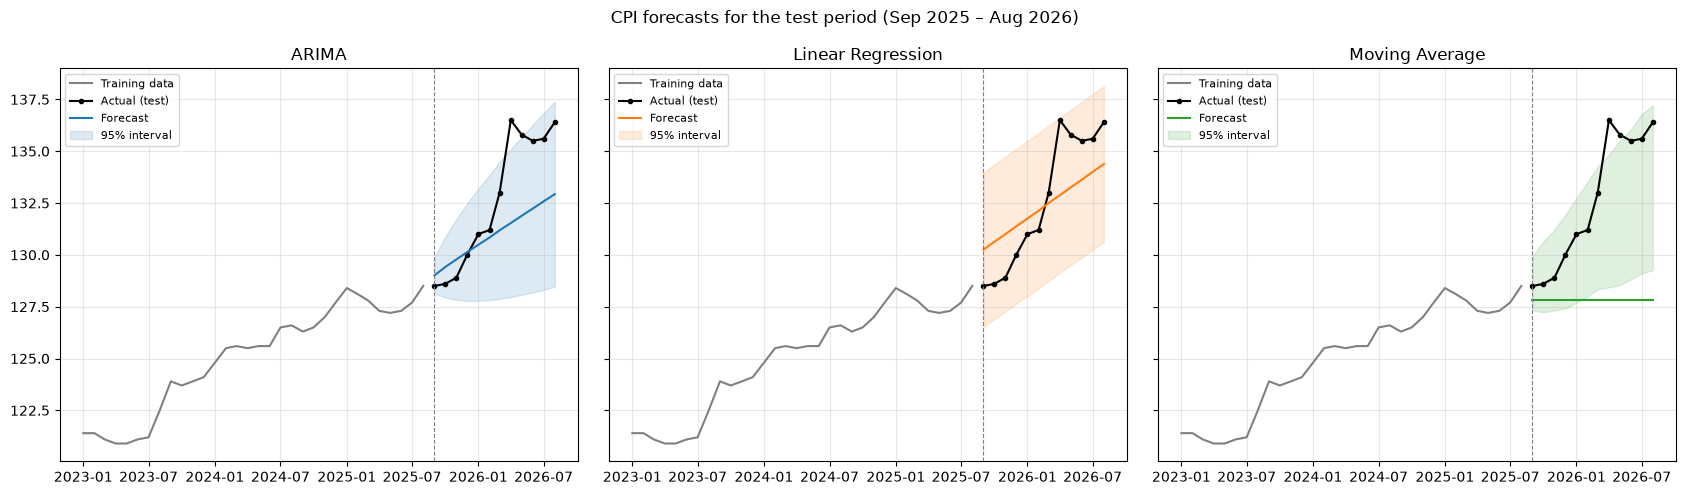

,actual,ARIMA,Linear Regression,Moving Average
2025-09-01,128.500,129.010,130.250,127.830
2025-10-01,128.600,129.410,130.630,127.830
2025-11-01,128.900,129.780,131.000,127.830
2025-12-01,130.000,130.140,131.380,127.830
2026-01-01,131.000,130.490,131.750,127.830
2026-02-01,131.200,130.840,132.130,127.830
2026-03-01,133.000,131.190,132.500,127.830
2026-04-01,136.500,131.530,132.880,127.830
2026-05-01,135.800,131.880,133.250,127.830
2026-06-01,135.500,132.230,133.630,127.830


In [15]:
COLORS = {'ARIMA': 'tab:blue', 'Linear Regression': 'tab:orange', 'Moving Average': 'tab:green'}
history = cpi['2023-01':config.TRAIN_END]

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, (name, r) in zip(axes.flat, results.items()):
    ax.plot(history, color='grey', label='Training data')
    ax.plot(test, color='black', marker='o', markersize=3, label='Actual (test)')
    ax.plot(r.forecast, color=COLORS[name], label='Forecast')
    ax.fill_between(r.forecast.index, r.lower, r.upper, color=COLORS[name], alpha=0.15,
                    label='95% interval')
    ax.axvline(config.TEST_START, color='grey', linestyle='--', linewidth=0.8)
    ax.set_title(name)
    ax.legend(fontsize=8, loc='upper left')
fig.suptitle('CPI forecasts for the test period (Sep 2025 – Aug 2026)')
fig.tight_layout()
plt.show()

forecast_table = pd.DataFrame({'actual': test, **{name: r.forecast for name, r in results.items()}})
display(forecast_table.round(2))

## Experimental Results and Evaluation

In [17]:
inf_series = (
    inf_raw.assign(area=inf_raw['area'].str.lstrip('.').str.strip())
      .query("area == 'PHILIPPINES' and category == '0 - ALL ITEMS'")
      .set_index('date')['value']
      .sort_index()
      .asfreq('MS')
)
pp_series = (
    pp_raw.assign(area=pp_raw['area'].str.lstrip('.').str.strip())
      .query("area == 'PHILIPPINES'")
      .set_index('date')['value']
      .sort_index()
      .asfreq('MS')
)
actuals = {'cpi': cpi, 'inflation': inf_series, 'purchasing_power': pp_series}
_, main = ev.forecast_from(cpi, config.TRAIN_END)
main = ev.attach_actuals(main, actuals)

for label, (start, end) in config.TEST_SUBPERIODS.items():
    m = ev.metrics_table(main, start, end)
    print('\n###', label)
    pivot = m.pivot(index='model', columns='variable', values=config.METRICS)
    pivot = pivot.swaplevel(axis=1)[[v for v in config.VARIABLES]]
    pivot = pivot.reindex(columns=config.METRICS, level=1).rename(columns={'cpi':'CPI','inflation':'Inflation','purchasing_power':'Purchasing power'}, level=0)
    display(pivot.reindex(config.PROPOSAL_MODELS).round(3))


### full test (Sep 2025 - Aug 2026)


variable            CPI             Inflation              Purchasing power  \
                    MAE  RMSE  MAPE       MAE  RMSE   MAPE              MAE   
model                                                                         
ARIMA             1.972 2.537 1.463     1.550 1.992 33.493            0.012   
Linear Regression 1.758 1.935 1.321     1.375 1.510 46.298            0.009   
Moving Average    4.750 5.671 3.530     3.708 4.436 85.687            0.025   

variable                       
                   RMSE  MAPE  
model                          
ARIMA             0.015 1.568  
Linear Regression 0.011 1.216  
Moving Average    0.031 3.373


### before shock (Sep 2025 - Feb 2026)


variable            CPI             Inflation              Purchasing power  \
                    MAE  RMSE  MAPE       MAE  RMSE   MAPE              MAE   
model                                                                         
ARIMA             0.535 0.592 0.414     0.417 0.460 23.924            0.005   
Linear Regression 1.490 1.578 1.152     1.183 1.256 68.347            0.008   
Moving Average    1.867 2.169 1.432     1.433 1.666 73.469            0.008   

variable                       
                   RMSE  MAPE  
model                          
ARIMA             0.007 0.647  
Linear Regression 0.011 1.071  
Moving Average    0.012 1.094


### after shock (Mar 2026 - Aug 2026)


variable            CPI             Inflation              Purchasing power  \
                    MAE  RMSE  MAPE       MAE  RMSE   MAPE              MAE   
model                                                                         
ARIMA             3.409 3.539 2.512     2.683 2.780 43.062            0.018   
Linear Regression 2.026 2.235 1.490     1.567 1.727 24.248            0.010   
Moving Average    7.633 7.722 5.628     5.983 6.049 97.904            0.042   

variable                       
                   RMSE  MAPE  
model                          
ARIMA             0.020 2.490  
Linear Regression 0.012 1.361  
Moving Average    0.042 5.652

In [18]:
rolling, fold_metrics = ev.rolling_origin(cpi, actuals)
print('Average over the five rolling-origin folds (pooled CPI focus):')
avg = ev.average_over_folds(fold_metrics)
display(avg[avg['variable']=='cpi'].round(3))

Average over the five rolling-origin folds (pooled CPI focus):


,model,variable,MAE,RMSE,MAPE
0,ARIMA,cpi,1.658,1.834,1.334
3,Linear Regression,cpi,2.858,2.961,2.321
6,Moving Average,cpi,2.655,2.928,2.141


In [20]:
pooled = pd.concat([rolling, main], ignore_index=True)
pooled_metrics = ev.metrics_table(pooled)
pivot = pooled_metrics.pivot(index='model', columns='variable', values=config.METRICS)
pivot = pivot.swaplevel(axis=1)[[v for v in config.VARIABLES]]
pivot = pivot.reindex(columns=config.METRICS, level=1).rename(columns={'cpi':'CPI','inflation':'Inflation','purchasing_power':'Purchasing power'}, level=0)
display(pivot.reindex(config.PROPOSAL_MODELS).round(3))

variable            CPI             Inflation              Purchasing power  \
                    MAE  RMSE  MAPE       MAE  RMSE   MAPE              MAE   
model                                                                         
ARIMA             1.710 2.009 1.356     1.419 1.661 42.717            0.012   
Linear Regression 2.674 3.144 2.155     2.254 2.693 56.026            0.017   
Moving Average    3.004 3.710 2.373     2.479 3.053 63.313            0.016   

variable                       
                   RMSE  MAPE  
model                          
ARIMA             0.014 1.449  
Linear Regression 0.021 2.044  
Moving Average    0.021 2.041

In [21]:
rows = []
for basis_label, metrics in [('Pooled, six origins (selection basis)', pooled_metrics),
                             ('Main test only (original plan)', ev.metrics_table(main, config.TEST_START, config.TEST_END))]:
    winner, explanation, wins = ev.select_model(metrics, models=config.PROPOSAL_MODELS)
    rows.append({'evaluation': basis_label, 'models': 'ARIMA, Linear Regression, Moving Average',
                 'winner': winner, 'reason': explanation})
pd.set_option('display.max_colwidth', None)
display(pd.DataFrame(rows))


,evaluation,models,winner,reason
0,"Pooled, six origins (selection basis)","ARIMA, Linear Regression, Moving Average",ARIMA,"ARIMA has the lowest MAE, RMSE, MAPE (3 of 3 metrics)."
1,Main test only (original plan),"ARIMA, Linear Regression, Moving Average",Linear Regression,"Linear Regression has the lowest MAE, RMSE, MAPE (3 of 3 metrics)."


In [22]:
final_model, explanation, wins, _ = ev.select_final_model(main, rolling)
print(f'Selection basis: {config.SELECTION_BASIS}')
print(f'Final model: {final_model}')
print(explanation)
print('Metric wins:', {k: int(v) for k, v in wins.items()})

Selection basis: pooled
Final model: ARIMA
ARIMA has the lowest MAE, RMSE, MAPE (3 of 3 metrics).
Metric wins: {'ARIMA': 3, 'Linear Regression': 0, 'Moving Average': 0}


model,ARIMA,Linear Regression,Moving Average
step,,,
1,0.494,2.545,0.889
2,0.875,2.438,1.039
3,1.183,2.481,1.406
4,1.185,2.324,1.839
5,1.541,2.667,2.739
6,1.437,2.710,3.072
7,1.705,2.615,3.472
8,2.497,3.010,3.922
9,2.432,2.821,3.922


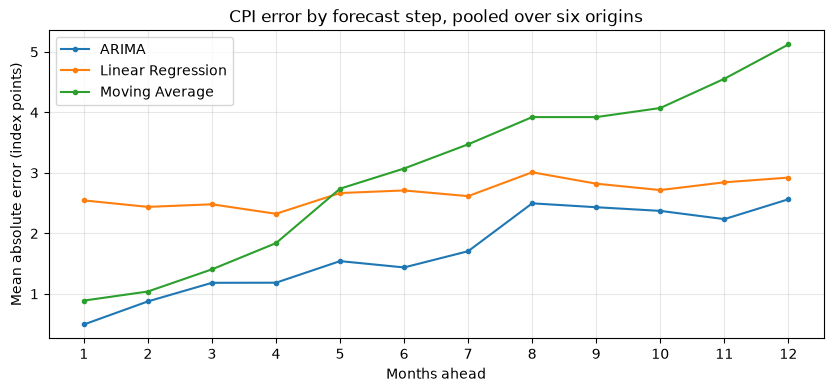

In [24]:
MODEL_ORDER = config.PROPOSAL_MODELS
by_step = ev.error_by_step(pooled)[MODEL_ORDER]
display(by_step.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
for model in MODEL_ORDER:
    ax.plot(by_step.index, by_step[model], marker='o', markersize=3,
            color=COLORS[model],
            linestyle='-',
            label=model + (''))
ax.set_xlabel('Months ahead')
ax.set_ylabel('Mean absolute error (index points)')
ax.set_title('CPI error by forecast step, pooled over six origins')
ax.set_xticks(range(1, config.HORIZON + 1))
ax.legend()
plt.show()

In [25]:
final_results, final_predictions = ev.forecast_from(cpi, config.DATA_END, models=[final_model])
final = final_results[final_model]
print(f'{final_model} settings on all data: {final.params}')

final_table = derive_all(cpi, final.forecast)
final_table['cpi_lower'], final_table['cpi_upper'] = final.lower, final.upper
display(final_table.round(2))

import json
info = json.loads((OUT / 'model_info.json').read_text(encoding='utf-8'))
print('\nSaved outputs:', [p.name for p in sorted(OUT.glob('*'))])
print('Final model recorded in model_info.json:', info['final_model'])

ARIMA settings on all data: {'order': (0, 1, 1), 'seasonal_order': (0, 0, 0, 0), 'aic': np.float64(179.1990449090025), 'drift_per_month': 0.3830893366197122}


,cpi,inflation,purchasing_power,cpi_lower,cpi_upper
2026-09-01,136.950,6.600,0.730,135.850,138.050
2026-10-01,137.330,6.800,0.730,135.510,139.160
2026-11-01,137.710,6.800,0.730,135.380,140.050
2026-12-01,138.100,6.200,0.720,135.340,140.850
2027-01-01,138.480,5.700,0.720,135.360,141.600
2027-02-01,138.860,5.800,0.720,135.420,142.310
2027-03-01,139.250,4.700,0.720,135.510,142.990
2027-04-01,139.630,2.300,0.720,135.620,143.640
2027-05-01,140.010,3.100,0.710,135.740,144.280
2027-06-01,140.400,3.600,0.710,135.880,144.910



Saved outputs: ['error_by_step.csv', 'forecasts.csv', 'metrics.csv', 'model_info.json', 'README.md', 'test_predictions.csv']
Final model recorded in model_info.json: ARIMA


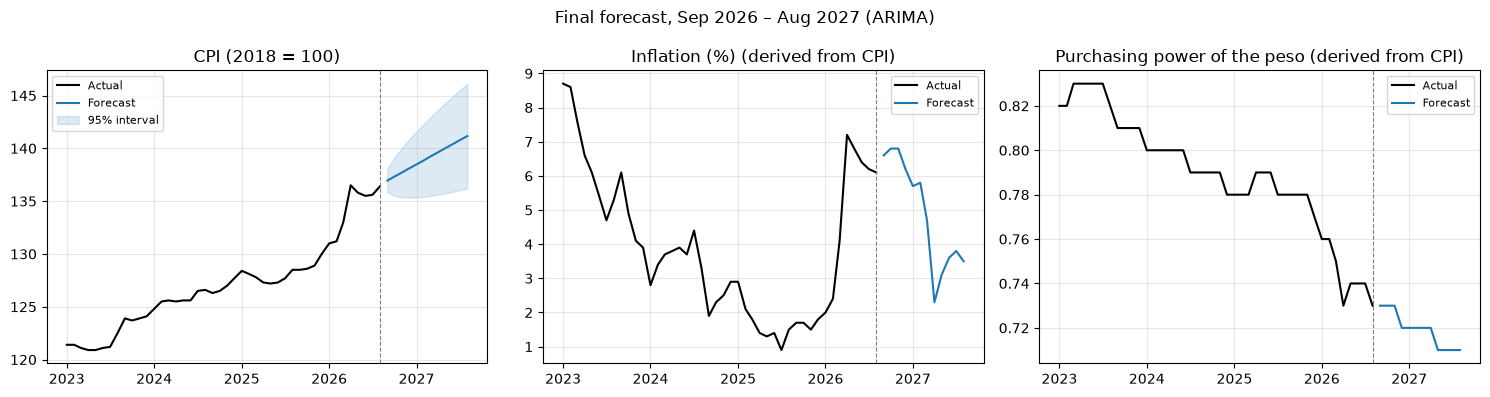

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
history_start = '2023-01'
inf_hist = actuals['inflation']
pp_hist = actuals['purchasing_power']

axes[0].plot(cpi[history_start:], color='black', label='Actual')
axes[0].plot(final.forecast, color=COLORS[final_model], label='Forecast')
axes[0].fill_between(final.forecast.index, final.lower, final.upper, color=COLORS[final_model], alpha=0.15,
                     label='95% interval')
axes[0].set_title('CPI (2018 = 100)')
axes[0].legend(fontsize=8)

axes[1].plot(inf_hist[history_start:], color='black', label='Actual')
axes[1].plot(final_table['inflation'], color=COLORS[final_model], label='Forecast')
axes[1].set_title('Inflation (%) (derived from CPI)')
axes[1].legend(fontsize=8)

axes[2].plot(pp_hist[history_start:], color='black', label='Actual')
axes[2].plot(final_table['purchasing_power'], color=COLORS[final_model], label='Forecast')
axes[2].set_title('Purchasing power of the peso (derived from CPI)')
axes[2].legend(fontsize=8)

for ax in axes:
    ax.axvline(config.DATA_END, color='grey', linestyle='--', linewidth=0.8)
fig.suptitle(f'Final forecast, Sep 2026 – Aug 2027 ({final_model})')
fig.tight_layout()
plt.show()